In [2]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# Cell 1 — Project Setup
# ============================================================

!pip -q install gradio pypdf python-docx nltk matplotlib wordcloud

import re
import os
import json
import math
import nltk
import gradio as gr
import matplotlib.pyplot as plt

from collections import Counter
from pypdf import PdfReader

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)

print("╔══════════════════════════════════════════════╗")
print("║       AI EXAM QUESTION PAPER ANALYZER       ║")
print("║                                              ║")
print("║  ✓ Libraries installed                      ║")
print("║  ✓ PDF processing ready                     ║")
print("║  ✓ NLP processing ready                     ║")
print("║  ✓ Gradio interface ready                   ║")
print("╚══════════════════════════════════════════════╝")

print("\n🚀 Project setup completed successfully!")

╔══════════════════════════════════════════════╗
║       AI EXAM QUESTION PAPER ANALYZER       ║
║                                              ║
║  ✓ Libraries installed                      ║
║  ✓ PDF processing ready                     ║
║  ✓ NLP processing ready                     ║
║  ✓ Gradio interface ready                   ║
╚══════════════════════════════════════════════╝

🚀 Project setup completed successfully!


In [3]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# Cell 2 — PDF Text Extraction Engine
# ============================================================

def extract_pdf_text(pdf_path):
    """Extract readable text from an uploaded PDF."""

    if pdf_path is None:
        return "⚠️ Please upload a question paper PDF."

    try:
        reader = PdfReader(pdf_path)

        if len(reader.pages) == 0:
            return "⚠️ The PDF contains no pages."

        extracted_pages = []

        for page_number, page in enumerate(reader.pages, start=1):
            text = page.extract_text()

            if text:
                extracted_pages.append(
                    f"\n--- PAGE {page_number} ---\n{text.strip()}"
                )

        if not extracted_pages:
            return (
                "❌ No readable text was found.\n\n"
                "This may be a scanned/image-only PDF."
            )

        final_text = "\n".join(extracted_pages)

        # Clean unnecessary spaces while preserving question structure
        final_text = re.sub(r"[ \t]+", " ", final_text)
        final_text = re.sub(r"\n{3,}", "\n\n", final_text)

        return final_text.strip()

    except Exception as error:
        return f"❌ Error while reading PDF:\n{error}"


# ------------------------------------------------------------
# Test function
# ------------------------------------------------------------

print("📄 PDF extraction engine loaded successfully!")
print("✅ Ready to read question papers.")

📄 PDF extraction engine loaded successfully!
✅ Ready to read question papers.


In [4]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# Cell 4 — AI Topic Detection Engine
# ============================================================

TOPIC_KEYWORDS = {

    "Computer Networks": [
        "network", "computer network", "lan", "wan", "man",
        "topology", "protocol", "tcp", "udp", "ip",
        "osi", "routing", "switching", "congestion",
        "flow control", "subnet", "ethernet", "dns", "http",
        "ftp", "smtp", "arp", "dhcp"
    ],

    "Database Management": [
        "database", "dbms", "sql", "query", "table",
        "normalization", "transaction", "acid", "index",
        "primary key", "foreign key", "join", "relational",
        "er model", "entity", "attribute", "deadlock"
    ],

    "Operating Systems": [
        "operating system", "process", "thread", "cpu",
        "scheduling", "deadlock", "memory management",
        "paging", "segmentation", "virtual memory",
        "file system", "synchronization", "semaphore"
    ],

    "Data Structures": [
        "data structure", "array", "linked list", "stack",
        "queue", "tree", "binary tree", "bst", "graph",
        "heap", "hashing", "sorting", "searching",
        "algorithm", "traversal"
    ],

    "Artificial Intelligence": [
        "artificial intelligence", "ai", "machine learning",
        "neural network", "deep learning", "classification",
        "regression", "clustering", "supervised",
        "unsupervised", "reinforcement", "nlp"
    ],

    "Web Technology": [
        "html", "css", "javascript", "web", "website",
        "http", "frontend", "backend", "dom", "bootstrap",
        "responsive", "form", "ajax", "json", "xml"
    ],

    "Cloud Computing": [
        "cloud", "cloud computing", "iaas", "paas", "saas",
        "virtualization", "aws", "azure", "deployment",
        "storage", "serverless", "container"
    ],

    "Cybersecurity": [
        "security", "cybersecurity", "cyber",
        "encryption", "decryption", "authentication",
        "authorization", "firewall", "malware", "phishing",
        "attack", "intrusion", "cryptography", "rsa", "aes"
    ]
}


def detect_topics(question):
    """Detect relevant academic topics from a question."""

    question_lower = question.lower()

    topic_scores = {}

    for topic, keywords in TOPIC_KEYWORDS.items():

        score = 0

        for keyword in keywords:
            if keyword.lower() in question_lower:
                # Give higher weight to multi-word concepts
                if " " in keyword:
                    score += 2
                else:
                    score += 1

        if score > 0:
            topic_scores[topic] = score

    # Sort topics by relevance
    ranked_topics = sorted(
        topic_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    if ranked_topics:
        return [topic for topic, score in ranked_topics[:2]]

    return ["General / Mixed"]


def analyze_question_topics(questions):
    """Analyze topics for every extracted question."""

    analyzed_questions = []

    for q in questions:

        topics = detect_topics(q["question"])

        analyzed_questions.append({
            "number": q["number"],
            "question": q["question"],
            "marks": q["marks"],
            "topics": topics
        })

    return analyzed_questions


def get_topic_frequency(analyzed_questions):
    """Calculate how frequently each topic appears."""

    topic_counter = Counter()

    for q in analyzed_questions:
        for topic in q["topics"]:
            topic_counter[topic] += 1

    return topic_counter


print("🧠 AI topic detection engine loaded!")
print("📚 Supported academic domains:", len(TOPIC_KEYWORDS))
print("✅ Topic analysis is ready!")

🧠 AI topic detection engine loaded!
📚 Supported academic domains: 8
✅ Topic analysis is ready!


In [5]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# Cell 5 — Marks & Difficulty Analysis
# ============================================================

EASY_WORDS = [
    "define", "list", "name", "state", "identify",
    "what is", "mention", "write short note"
]

MEDIUM_WORDS = [
    "explain", "describe", "discuss", "differentiate",
    "compare", "illustrate", "summarize", "outline"
]

HARD_WORDS = [
    "analyze", "analyse", "evaluate", "justify",
    "design", "develop", "derive", "prove",
    "implement", "calculate", "solve", "critically",
    "architecture", "algorithm"
]


def classify_marks(marks):
    """Classify questions based on mark value."""

    if marks is None:
        return "Marks Not Detected"

    if marks <= 2:
        return "Short Answer"

    elif marks <= 5:
        return "Medium Answer"

    elif marks <= 10:
        return "Long Answer"

    else:
        return "Very Long Answer"


def calculate_difficulty(question, marks):
    """Estimate difficulty using marks and question wording."""

    text = question.lower()

    easy_score = sum(word in text for word in EASY_WORDS)
    medium_score = sum(word in text for word in MEDIUM_WORDS)
    hard_score = sum(word in text for word in HARD_WORDS)

    # Marks contribute to difficulty
    if marks is not None:

        if marks <= 2:
            mark_score = 1

        elif marks <= 5:
            mark_score = 2

        elif marks <= 10:
            mark_score = 3

        else:
            mark_score = 4

    else:
        mark_score = 2

    # Keyword contribution
    keyword_score = (
        easy_score * 1 +
        medium_score * 2 +
        hard_score * 3
    )

    total_score = mark_score + keyword_score

    # Final classification
    if total_score <= 2:
        difficulty = "Easy"

    elif total_score <= 5:
        difficulty = "Medium"

    else:
        difficulty = "Hard"

    return difficulty, total_score


def detect_question_type(question):
    """Identify the type of academic question."""

    text = question.lower()

    if any(word in text for word in [
        "define", "what is", "state", "list", "name"
    ]):
        return "Definition / Recall"

    if any(word in text for word in [
        "explain", "describe", "discuss"
    ]):
        return "Explanation"

    if any(word in text for word in [
        "compare", "differentiate", "distinguish"
    ]):
        return "Comparison"

    if any(word in text for word in [
        "analyze", "analyse", "evaluate", "justify"
    ]):
        return "Analytical"

    if any(word in text for word in [
        "design", "develop", "implement"
    ]):
        return "Design / Implementation"

    if any(word in text for word in [
        "calculate", "solve", "derive", "prove"
    ]):
        return "Problem Solving"

    return "General / Theory"


def analyze_marks_and_difficulty(analyzed_questions):
    """Add marks category, difficulty and question type."""

    final_questions = []

    for q in analyzed_questions:

        marks_category = classify_marks(q["marks"])

        difficulty, difficulty_score = calculate_difficulty(
            q["question"],
            q["marks"]
        )

        question_type = detect_question_type(q["question"])

        final_questions.append({
            **q,
            "marks_category": marks_category,
            "difficulty": difficulty,
            "difficulty_score": difficulty_score,
            "question_type": question_type
        })

    return final_questions


print("🎯 Marks analyzer loaded!")
print("⚡ Difficulty analyzer loaded!")
print("📝 Question-type detector loaded!")
print("✅ Cell 5 completed successfully!")

🎯 Marks analyzer loaded!
⚡ Difficulty analyzer loaded!
📝 Question-type detector loaded!
✅ Cell 5 completed successfully!


In [6]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# Cell 6 — Repeated & Important Question Detection
# ============================================================

from difflib import SequenceMatcher


def clean_question_for_comparison(question):
    """Prepare question text for similarity comparison."""

    text = question.lower()

    # Remove common question words
    remove_words = [
        "what", "is", "are", "the", "a", "an",
        "explain", "describe", "discuss",
        "define", "write", "short", "note",
        "about", "with", "and", "or", "of", "in",
        "on", "to", "for"
    ]

    words = re.findall(r"[a-zA-Z]+", text)

    filtered_words = [
        word for word in words
        if word not in remove_words
    ]

    return " ".join(filtered_words)


def question_similarity(question1, question2):
    """Calculate similarity between two questions."""

    q1 = clean_question_for_comparison(question1)
    q2 = clean_question_for_comparison(question2)

    return SequenceMatcher(None, q1, q2).ratio()


def detect_repeated_questions(questions, threshold=0.65):
    """Detect identical or highly similar questions."""

    repeated_groups = []
    checked_pairs = set()

    for i in range(len(questions)):

        for j in range(i + 1, len(questions)):

            pair = (i, j)

            if pair in checked_pairs:
                continue

            checked_pairs.add(pair)

            similarity = question_similarity(
                questions[i]["question"],
                questions[j]["question"]
            )

            if similarity >= threshold:

                repeated_groups.append({
                    "question_1": questions[i]["number"],
                    "question_2": questions[j]["number"],
                    "similarity": round(similarity * 100, 1)
                })

    return repeated_groups


def calculate_importance_score(question, topic_frequency):
    """Calculate an exam importance score."""

    score = 0

    # Marks contribution
    marks = question["marks"]

    if marks is not None:

        if marks <= 2:
            score += 10

        elif marks <= 5:
            score += 25

        elif marks <= 10:
            score += 40

        else:
            score += 50

    # Topic frequency contribution
    topics = question["topics"]

    max_topic_frequency = max(
        topic_frequency.values(),
        default=1
    )

    for topic in topics:

        frequency = topic_frequency.get(topic, 1)

        topic_score = (
            frequency / max_topic_frequency
        ) * 30

        score += topic_score

    # Difficulty contribution
    if question["difficulty"] == "Hard":
        score += 20

    elif question["difficulty"] == "Medium":
        score += 10

    # Keep score between 0 and 100
    score = min(round(score), 100)

    return score


def rank_important_questions(questions, topic_frequency):
    """Rank questions according to exam importance."""

    ranked = []

    for q in questions:

        importance = calculate_importance_score(
            q,
            topic_frequency
        )

        ranked.append({
            **q,
            "importance_score": importance
        })

    ranked.sort(
        key=lambda x: x["importance_score"],
        reverse=True
    )

    return ranked


print("🔁 Repeated-question detector loaded!")
print("⭐ Importance scoring engine loaded!")
print("📊 Question ranking engine loaded!")
print("✅ Cell 6 completed successfully!")

🔁 Repeated-question detector loaded!
⭐ Importance scoring engine loaded!
📊 Question ranking engine loaded!
✅ Cell 6 completed successfully!


In [9]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# CELL 7 — COMPLETE SELF-CONTAINED ANALYZER
# ============================================================

import re
from collections import Counter
from difflib import SequenceMatcher


# ============================================================
# 1. QUESTION EXTRACTION
# ============================================================

def extract_questions(text):

    if not text:
        return []

    text = text.replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)

    pattern = (
        r"(?:^|\n)\s*"
        r"(?:Q(?:uestion)?\s*)?"
        r"(\d{1,3})\s*[\.\):\-]\s*"
        r"(.*?)(?="
        r"\n\s*(?:Q(?:uestion)?\s*)?"
        r"\d{1,3}\s*[\.\):\-]"
        r"|\Z)"
    )

    matches = re.findall(
        pattern,
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    questions = []

    for number, question_text in matches:

        question_text = question_text.strip()

        # Remove page markers
        question_text = re.sub(
            r"---\s*PAGE\s*\d+\s*---",
            "",
            question_text,
            flags=re.IGNORECASE
        )

        # Detect marks
        marks_match = re.search(
            r"\(\s*(\d{1,3})\s*(?:marks?|m)\s*\)",
            question_text,
            flags=re.IGNORECASE
        )

        if not marks_match:
            marks_match = re.search(
                r"[-–—]\s*(\d{1,3})\s*(?:marks?|m)\b",
                question_text,
                flags=re.IGNORECASE
            )

        marks = (
            int(marks_match.group(1))
            if marks_match
            else None
        )

        # Remove marks from question
        clean_question = re.sub(
            r"\(\s*\d{1,3}\s*(?:marks?|m)\s*\)",
            "",
            question_text,
            flags=re.IGNORECASE
        )

        clean_question = re.sub(
            r"[-–—]\s*\d{1,3}\s*(?:marks?|m)\b",
            "",
            clean_question,
            flags=re.IGNORECASE
        )

        clean_question = re.sub(
            r"\s+",
            " ",
            clean_question
        ).strip()

        if len(clean_question) >= 5:

            questions.append({
                "number": int(number),
                "question": clean_question,
                "marks": marks
            })

    return questions


# ============================================================
# 2. TOPIC DETECTION
# ============================================================

TOPIC_KEYWORDS = {

    "Computer Networks": [
        "network", "tcp", "udp", "ip", "osi",
        "routing", "switching", "congestion",
        "protocol", "ethernet", "dns", "http"
    ],

    "Database Management": [
        "database", "dbms", "sql", "query",
        "normalization", "transaction", "acid",
        "primary key", "foreign key", "join"
    ],

    "Operating Systems": [
        "operating system", "process", "thread",
        "cpu", "scheduling", "deadlock",
        "memory management", "paging",
        "virtual memory", "file system"
    ],

    "Data Structures": [
        "array", "linked list", "stack", "queue",
        "tree", "binary tree", "graph", "heap",
        "hashing", "sorting", "searching"
    ],

    "Artificial Intelligence": [
        "artificial intelligence", "machine learning",
        "neural network", "deep learning",
        "classification", "regression",
        "clustering", "nlp"
    ],

    "Web Technology": [
        "html", "css", "javascript", "web",
        "dom", "bootstrap", "responsive",
        "ajax", "json", "xml"
    ],

    "Cloud Computing": [
        "cloud", "iaas", "paas", "saas",
        "virtualization", "aws", "azure",
        "serverless", "container"
    ],

    "Cybersecurity": [
        "security", "cybersecurity", "encryption",
        "decryption", "authentication",
        "authorization", "firewall",
        "malware", "phishing", "cryptography"
    ]
}


def detect_topics(question):

    text = question.lower()
    scores = {}

    for topic, keywords in TOPIC_KEYWORDS.items():

        score = 0

        for keyword in keywords:

            if keyword in text:

                if " " in keyword:
                    score += 2
                else:
                    score += 1

        if score > 0:
            scores[topic] = score

    if not scores:
        return ["General / Mixed"]

    ranked = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return [topic for topic, score in ranked[:2]]


# ============================================================
# 3. DIFFICULTY ANALYSIS
# ============================================================

EASY_WORDS = [
    "define", "list", "name",
    "state", "identify", "what is"
]

MEDIUM_WORDS = [
    "explain", "describe",
    "discuss", "compare",
    "differentiate"
]

HARD_WORDS = [
    "analyze", "analyse",
    "evaluate", "justify",
    "design", "develop",
    "derive", "prove",
    "implement", "calculate",
    "solve"
]


def classify_marks(marks):

    if marks is None:
        return "Marks Not Detected"

    if marks <= 2:
        return "Short Answer"

    elif marks <= 5:
        return "Medium Answer"

    elif marks <= 10:
        return "Long Answer"

    return "Very Long Answer"


def calculate_difficulty(question, marks):

    text = question.lower()

    easy = sum(
        word in text
        for word in EASY_WORDS
    )

    medium = sum(
        word in text
        for word in MEDIUM_WORDS
    )

    hard = sum(
        word in text
        for word in HARD_WORDS
    )

    if marks is None:
        mark_score = 2

    elif marks <= 2:
        mark_score = 1

    elif marks <= 5:
        mark_score = 2

    elif marks <= 10:
        mark_score = 3

    else:
        mark_score = 4

    total = (
        mark_score +
        easy +
        medium * 2 +
        hard * 3
    )

    if total <= 2:
        level = "Easy"

    elif total <= 5:
        level = "Medium"

    else:
        level = "Hard"

    return level, total


# ============================================================
# 4. QUESTION TYPE
# ============================================================

def detect_question_type(question):

    text = question.lower()

    if any(
        word in text
        for word in [
            "define",
            "what is",
            "state",
            "list",
            "name"
        ]
    ):
        return "Definition / Recall"

    if any(
        word in text
        for word in [
            "explain",
            "describe",
            "discuss"
        ]
    ):
        return "Explanation"

    if any(
        word in text
        for word in [
            "compare",
            "differentiate",
            "distinguish"
        ]
    ):
        return "Comparison"

    if any(
        word in text
        for word in [
            "analyze",
            "analyse",
            "evaluate",
            "justify"
        ]
    ):
        return "Analytical"

    if any(
        word in text
        for word in [
            "design",
            "develop",
            "implement"
        ]
    ):
        return "Design / Implementation"

    if any(
        word in text
        for word in [
            "calculate",
            "solve",
            "derive",
            "prove"
        ]
    ):
        return "Problem Solving"

    return "General / Theory"


# ============================================================
# 5. COMPLETE QUESTION ANALYSIS
# ============================================================

def analyze_questions(questions):

    analyzed = []

    for q in questions:

        difficulty, difficulty_score = calculate_difficulty(
            q["question"],
            q["marks"]
        )

        analyzed.append({

            "number": q["number"],

            "question": q["question"],

            "marks": q["marks"],

            "marks_category": classify_marks(
                q["marks"]
            ),

            "topics": detect_topics(
                q["question"]
            ),

            "difficulty": difficulty,

            "difficulty_score": difficulty_score,

            "question_type": detect_question_type(
                q["question"]
            )
        })

    return analyzed


# ============================================================
# 6. TOPIC FREQUENCY
# ============================================================

def get_topic_frequency(questions):

    counter = Counter()

    for q in questions:

        for topic in q["topics"]:
            counter[topic] += 1

    return counter


# ============================================================
# 7. REPEATED QUESTION DETECTION
# ============================================================

def clean_for_similarity(text):

    words = re.findall(
        r"[a-zA-Z]+",
        text.lower()
    )

    stop_words = {
        "what", "is", "are",
        "the", "a", "an",
        "explain", "describe",
        "discuss", "define",
        "write", "about",
        "with", "and", "or",
        "of", "in", "to"
    }

    return " ".join(
        word
        for word in words
        if word not in stop_words
    )


def detect_repeated_questions(
    questions,
    threshold=0.65
):

    repeated = []

    for i in range(len(questions)):

        for j in range(i + 1, len(questions)):

            q1 = clean_for_similarity(
                questions[i]["question"]
            )

            q2 = clean_for_similarity(
                questions[j]["question"]
            )

            similarity = SequenceMatcher(
                None,
                q1,
                q2
            ).ratio()

            if similarity >= threshold:

                repeated.append({

                    "question_1":
                        questions[i]["number"],

                    "question_2":
                        questions[j]["number"],

                    "similarity":
                        round(similarity * 100, 1)
                })

    return repeated


# ============================================================
# 8. IMPORTANCE SCORE
# ============================================================

def calculate_importance(
    question,
    topic_frequency
):

    score = 0

    marks = question["marks"]

    if marks is not None:

        if marks <= 2:
            score += 10

        elif marks <= 5:
            score += 25

        elif marks <= 10:
            score += 40

        else:
            score += 50

    max_frequency = max(
        topic_frequency.values(),
        default=1
    )

    for topic in question["topics"]:

        frequency = topic_frequency.get(
            topic,
            1
        )

        score += (
            frequency / max_frequency
        ) * 30

    if question["difficulty"] == "Hard":
        score += 20

    elif question["difficulty"] == "Medium":
        score += 10

    return min(
        round(score),
        100
    )


# ============================================================
# 9. FINAL STATISTICS
# ============================================================

def generate_statistics(questions):

    topic_frequency = get_topic_frequency(
        questions
    )

    difficulty = Counter(
        q["difficulty"]
        for q in questions
    )

    question_types = Counter(
        q["question_type"]
        for q in questions
    )

    marks = [
        q["marks"]
        for q in questions
        if q["marks"] is not None
    ]

    return {

        "total_questions":
            len(questions),

        "total_marks":
            sum(marks),

        "average_marks":
            round(
                sum(marks) / len(marks),
                2
            ) if marks else 0,

        "easy":
            difficulty["Easy"],

        "medium":
            difficulty["Medium"],

        "hard":
            difficulty["Hard"],

        "topic_frequency":
            topic_frequency,

        "question_types":
            question_types
    }


# ============================================================
# 10. BUILT-IN TEST PAPER
# ============================================================

sample_paper = """

COMPUTER NETWORKS

Q1. Define computer network. (2 Marks)

Q2. Explain the OSI reference model. (5 Marks)

Q3. Compare TCP and UDP protocols. (5 Marks)

Q4. Explain congestion control mechanisms. (10 Marks)

Q5. What is routing? (2 Marks)

Q6. Explain TCP/IP architecture. (10 Marks)

"""


# ============================================================
# RUN COMPLETE TEST
# ============================================================

questions = extract_questions(
    sample_paper
)

analyzed_questions = analyze_questions(
    questions
)

statistics = generate_statistics(
    analyzed_questions
)

repeated_questions = detect_repeated_questions(
    analyzed_questions
)


# Add importance scores
for q in analyzed_questions:

    q["importance_score"] = calculate_importance(
        q,
        statistics["topic_frequency"]
    )


# Sort by importance
important_questions = sorted(
    analyzed_questions,
    key=lambda x: x["importance_score"],
    reverse=True
)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 60)
print("        🧠 AI EXAM QUESTION PAPER ANALYZER")
print("=" * 60)

print(
    f"\n📚 Total Questions : "
    f"{statistics['total_questions']}"
)

print(
    f"🎯 Total Marks     : "
    f"{statistics['total_marks']}"
)

print(
    f"📊 Average Marks   : "
    f"{statistics['average_marks']}"
)


print("\n⚡ DIFFICULTY")
print("-" * 40)

print(f"Easy   : {statistics['easy']}")
print(f"Medium : {statistics['medium']}")
print(f"Hard   : {statistics['hard']}")


print("\n🔥 TOP TOPICS")
print("-" * 40)

for topic, count in statistics[
    "topic_frequency"
].most_common():

    print(
        f"• {topic}: "
        f"{count} questions"
    )


print("\n⭐ IMPORTANT QUESTIONS")
print("-" * 40)

for q in important_questions[:5]:

    print(
        f"Q{q['number']} "
        f"→ {q['importance_score']}/100"
    )

    print(
        f"   {q['question']}"
    )


print("\n🔁 REPEATED / SIMILAR QUESTIONS")
print("-" * 40)

if repeated_questions:

    for item in repeated_questions:

        print(
            f"Q{item['question_1']} ↔ "
            f"Q{item['question_2']} "
            f"→ {item['similarity']}% similar"
        )

else:

    print("No highly similar questions detected.")


print("\n" + "=" * 60)
print("✅ CELL 7 COMPLETED SUCCESSFULLY!")
print("=" * 60)


        🧠 AI EXAM QUESTION PAPER ANALYZER

📚 Total Questions : 6
🎯 Total Marks     : 34
📊 Average Marks   : 5.67

⚡ DIFFICULTY
----------------------------------------
Easy   : 2
Medium : 4
Hard   : 0

🔥 TOP TOPICS
----------------------------------------
• Computer Networks: 6 questions

⭐ IMPORTANT QUESTIONS
----------------------------------------
Q4 → 80/100
   Explain congestion control mechanisms.
Q6 → 80/100
   Explain TCP/IP architecture.
Q2 → 65/100
   Explain the OSI reference model.
Q3 → 65/100
   Compare TCP and UDP protocols.
Q1 → 40/100
   Define computer network.

🔁 REPEATED / SIMILAR QUESTIONS
----------------------------------------
No highly similar questions detected.

✅ CELL 7 COMPLETED SUCCESSFULLY!


          📊 VISUAL ANALYTICS

⚡ Difficulty Distribution


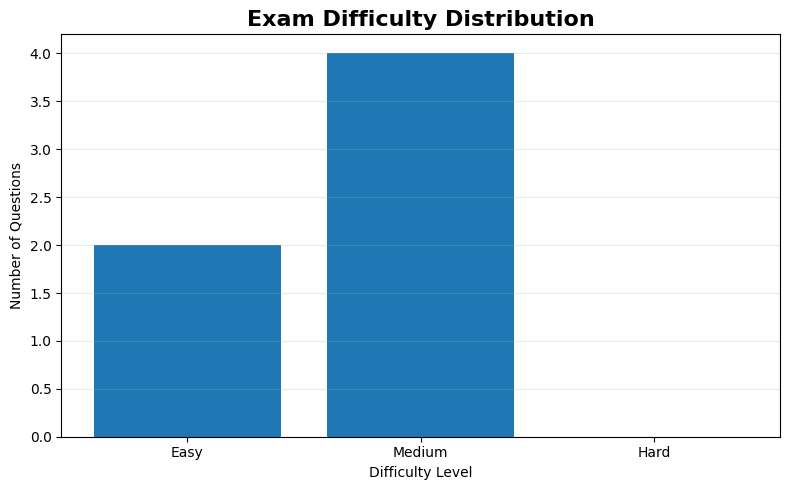


🔥 Topic Frequency


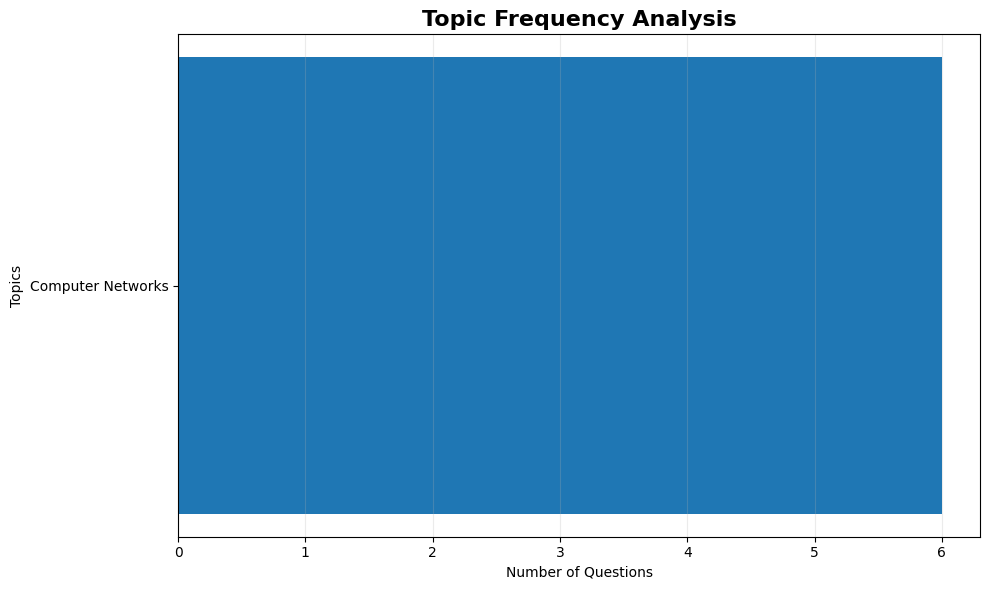


🎯 Marks Distribution


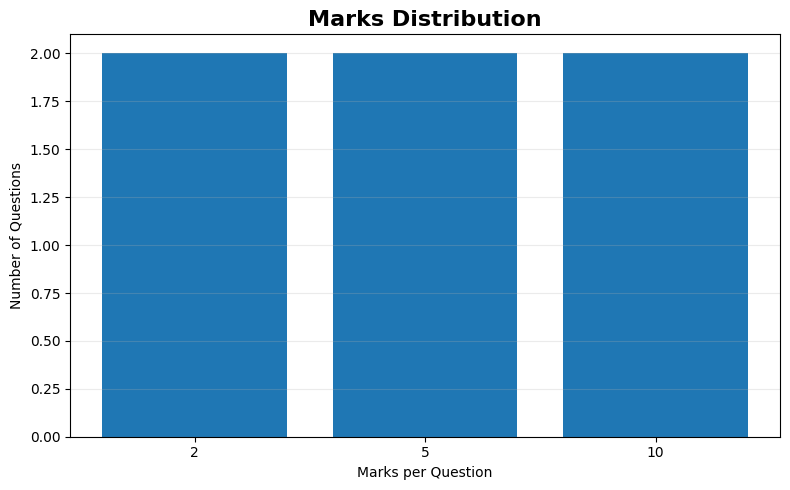


✅ Visual analytics generated successfully!


In [10]:
# ============================================================
# AI EXAM QUESTION PAPER ANALYZER
# CELL 8 — VISUAL ANALYTICS
# ============================================================

import matplotlib.pyplot as plt


def create_difficulty_chart(questions):
    """Create difficulty distribution chart."""

    difficulty_counts = Counter(
        q["difficulty"]
        for q in questions
    )

    labels = ["Easy", "Medium", "Hard"]

    values = [
        difficulty_counts.get("Easy", 0),
        difficulty_counts.get("Medium", 0),
        difficulty_counts.get("Hard", 0)
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(labels, values)

    plt.title(
        "Exam Difficulty Distribution",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel("Difficulty Level")
    plt.ylabel("Number of Questions")

    plt.grid(
        axis="y",
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


def create_topic_chart(questions):
    """Create topic frequency chart."""

    topic_counter = get_topic_frequency(
        questions
    )

    if not topic_counter:
        print("⚠️ No topics detected.")
        return

    topics = [
        item[0]
        for item in topic_counter.most_common()
    ]

    counts = [
        item[1]
        for item in topic_counter.most_common()
    ]

    plt.figure(
        figsize=(10, 6)
    )

    plt.barh(
        topics[::-1],
        counts[::-1]
    )

    plt.title(
        "Topic Frequency Analysis",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Number of Questions"
    )

    plt.ylabel(
        "Topics"
    )

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


def create_marks_chart(questions):
    """Create marks distribution chart."""

    marks_counter = Counter()

    for q in questions:

        marks = q.get("marks")

        if marks is not None:
            marks_counter[marks] += 1

    if not marks_counter:
        print("⚠️ No marks detected.")
        return

    marks = sorted(
        marks_counter.keys()
    )

    counts = [
        marks_counter[m]
        for m in marks
    ]

    plt.figure(
        figsize=(8, 5)
    )

    plt.bar(
        [str(m) for m in marks],
        counts
    )

    plt.title(
        "Marks Distribution",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Marks per Question"
    )

    plt.ylabel(
        "Number of Questions"
    )

    plt.grid(
        axis="y",
        alpha=0.25
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# DISPLAY ALL CHARTS
# ============================================================

print("=" * 55)
print("          📊 VISUAL ANALYTICS")
print("=" * 55)

print("\n⚡ Difficulty Distribution")
create_difficulty_chart(
    analyzed_questions
)

print("\n🔥 Topic Frequency")
create_topic_chart(
    analyzed_questions
)

print("\n🎯 Marks Distribution")
create_marks_chart(
    analyzed_questions
)

print("\n✅ Visual analytics generated successfully!")

In [12]:
# ============================================================
# CELL 9 — EXAM LENS AI : LIGHT PROFESSIONAL DASHBOARD
# ============================================================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


# ============================================================
# PDF ANALYSIS
# ============================================================

def analyze_uploaded_pdf(pdf_path):

    if pdf_path is None:
        return (
            "⚠️ Please upload a PDF question paper.",
            pd.DataFrame(),
            "No analysis available.",
            "No repeated questions detected.",
            None, None, None
        )

    try:

        text = extract_pdf_text(pdf_path)

        if not text.strip():
            return (
                "❌ Could not extract text from this PDF.",
                pd.DataFrame(),
                "No analysis available.",
                "No repeated questions detected.",
                None, None, None
            )

        questions = extract_questions(text)

        if not questions:
            return (
                "❌ No questions detected in the PDF.",
                pd.DataFrame(),
                "No analysis available.",
                "No repeated questions detected.",
                None, None, None
            )

        analyzed = analyze_questions(questions)

        stats = generate_statistics(analyzed)

        topic_frequency = stats["topic_frequency"]

        for q in analyzed:
            q["importance_score"] = calculate_importance(
                q,
                topic_frequency
            )

        important = sorted(
            analyzed,
            key=lambda x: x["importance_score"],
            reverse=True
        )

        repeated = detect_repeated_questions(analyzed)

        # ====================================================
        # SUMMARY
        # ====================================================

        summary = f"""
        <div class="summary-grid">

            <div class="stat-card purple">
                <div class="stat-number">
                    {stats['total_questions']}
                </div>
                <div class="stat-label">
                    Total Questions
                </div>
            </div>

            <div class="stat-card teal">
                <div class="stat-number">
                    {stats['total_marks']}
                </div>
                <div class="stat-label">
                    Total Marks
                </div>
            </div>

            <div class="stat-card orange">
                <div class="stat-number">
                    {stats['average_marks']}
                </div>
                <div class="stat-label">
                    Average Marks
                </div>
            </div>

            <div class="stat-card pink">
                <div class="stat-number">
                    {stats['hard_questions']}
                </div>
                <div class="stat-label">
                    Hard Questions
                </div>
            </div>

        </div>
        """

        # ====================================================
        # QUESTION TABLE
        # ====================================================

        table_data = []

        for q in analyzed:

            topics = (
                ", ".join(q["topics"])
                if q["topics"]
                else "General"
            )

            table_data.append([
                q["number"],
                q["question"],
                q["marks"],
                topics,
                q["difficulty"],
                q["question_type"],
                q["importance_score"]
            ])

        dataframe = pd.DataFrame(
            table_data,
            columns=[
                "Question",
                "Question Text",
                "Marks",
                "Topic",
                "Difficulty",
                "Type",
                "Importance Score"
            ]
        )

        # ====================================================
        # IMPORTANT QUESTIONS
        # ====================================================

        important_md = "## ⭐ Most Important Questions\n\n"

        for index, q in enumerate(important[:10], 1):

            topic_text = (
                ", ".join(q["topics"])
                if q["topics"]
                else "General"
            )

            important_md += f"""
### {index}. Q{q['number']} — {q['marks']} Marks

**{q['question']}**

📚 Topic: **{topic_text}**

🔥 Importance Score: **{q['importance_score']}**

---
"""

        # ====================================================
        # REPEATED QUESTIONS
        # ====================================================

        if repeated:

            repeated_md = "## 🔁 Similar / Repeated Questions\n\n"

            for pair in repeated:

                repeated_md += f"""
**Q{pair[0]} ↔ Q{pair[1]}**

Similarity: **{pair[2]}%**

---
"""

        else:

            repeated_md = """
## 🔁 Similar / Repeated Questions

✅ No highly similar questions detected.
"""

        # ====================================================
        # DIFFICULTY CHART
        # ====================================================

        difficulty_counts = Counter(
            q["difficulty"] for q in analyzed
        )

        fig1 = plt.figure(figsize=(7, 4))

        labels = ["Easy", "Medium", "Hard"]

        values = [
            difficulty_counts.get("Easy", 0),
            difficulty_counts.get("Medium", 0),
            difficulty_counts.get("Hard", 0)
        ]

        plt.bar(labels, values)

        plt.title(
            "Difficulty Distribution",
            fontsize=15,
            fontweight="bold"
        )

        plt.xlabel("Difficulty Level")
        plt.ylabel("Number of Questions")

        plt.grid(
            axis="y",
            alpha=0.2
        )

        plt.tight_layout()

        # ====================================================
        # TOPIC CHART
        # ====================================================

        fig2 = plt.figure(figsize=(8, 5))

        topics = list(topic_frequency.keys())[:8]

        counts = [
            topic_frequency[t]
            for t in topics
        ]

        if topics:
            plt.barh(
                topics[::-1],
                counts[::-1]
            )

        plt.title(
            "Top Exam Topics",
            fontsize=15,
            fontweight="bold"
        )

        plt.xlabel("Number of Questions")

        plt.tight_layout()

        # ====================================================
        # MARKS CHART
        # ====================================================

        fig3 = plt.figure(figsize=(7, 4))

        marks_counter = Counter(
            q["marks"]
            for q in analyzed
        )

        marks = sorted(
            marks_counter.keys()
        )

        counts = [
            marks_counter[m]
            for m in marks
        ]

        plt.bar(
            [str(m) for m in marks],
            counts
        )

        plt.title(
            "Marks Distribution",
            fontsize=15,
            fontweight="bold"
        )

        plt.xlabel("Marks")
        plt.ylabel("Questions")

        plt.tight_layout()

        return (
            summary,
            dataframe,
            important_md,
            repeated_md,
            fig1,
            fig2,
            fig3
        )

    except Exception as e:

        return (
            f"❌ Error: {str(e)}",
            pd.DataFrame(),
            "Analysis failed.",
            "Analysis failed.",
            None, None, None
        )


# ============================================================
# PROFESSIONAL LIGHT THEME
# ============================================================

custom_css = """

/* MAIN BACKGROUND */

body {
    background:
        linear-gradient(
            135deg,
            #fffaf5 0%,
            #f7f3ff 50%,
            #eefbf8 100%
        ) !important;
}


/* MAIN CONTAINER */

.gradio-container {
    max-width: 1250px !important;
    margin: auto !important;
    background: transparent !important;
}


/* HERO */

.hero {
    text-align: center;
    padding: 42px 25px;
    margin-bottom: 25px;

    border-radius: 28px;

    background:
        linear-gradient(
            135deg,
            #ffffff,
            #f5efff
        );

    border: 1px solid #e5daf7;

    box-shadow:
        0 12px 35px
        rgba(91, 61, 130, 0.12);
}

.hero h1 {
    font-size: 44px;
    font-weight: 800;

    color: #43215f;

    margin-bottom: 8px;
}

.hero p {
    color: #665b70;
    font-size: 17px;
}


/* UPLOAD AREA */

.upload-box {
    background: #ffffff !important;

    border: 2px dashed #a879d9 !important;

    border-radius: 20px !important;

    box-shadow:
        0 8px 25px
        rgba(90, 50, 120, 0.08);
}


/* BUTTON */

.analyze-btn {
    background:
        linear-gradient(
            90deg,
            #7048a8,
            #279f91
        ) !important;

    color: white !important;

    font-size: 17px !important;

    font-weight: 700 !important;

    border: none !important;

    border-radius: 15px !important;

    min-height: 55px !important;

    box-shadow:
        0 8px 20px
        rgba(112,72,168,0.22);
}


/* BUTTON HOVER */

.analyze-btn:hover {
    transform: translateY(-2px);

    box-shadow:
        0 12px 25px
        rgba(112,72,168,0.28);
}


/* SUMMARY GRID */

.summary-grid {
    display: grid;

    grid-template-columns:
        repeat(4, 1fr);

    gap: 18px;

    margin: 15px 0 25px;
}


/* CARDS */

.stat-card {
    padding: 23px;

    border-radius: 20px;

    background: #ffffff;

    text-align: center;

    box-shadow:
        0 8px 25px
        rgba(70,50,90,0.10);

    border: 1px solid #eee7f5;
}


/* CARD NUMBER */

.stat-number {
    font-size: 34px;

    font-weight: 800;

    margin-bottom: 5px;
}


/* CARD LABEL */

.stat-label {
    color: #6c6472;

    font-size: 14px;

    font-weight: 600;
}


/* CARD VARIANTS */

.purple .stat-number {
    color: #7048a8;
}

.teal .stat-number {
    color: #279f91;
}

.orange .stat-number {
    color: #d88635;
}

.pink .stat-number {
    color: #c05b86;
}


/* MARKDOWN */

.markdown-text,
.prose {
    color: #332d38 !important;
}


/* TABLE */

table {
    background: white !important;
    border-radius: 15px !important;
}


/* PLOT CARDS */

.plot-container {
    background: white !important;

    border-radius: 18px !important;

    padding: 10px !important;

    box-shadow:
        0 7px 22px
        rgba(70,50,90,0.08);
}


/* MOBILE */

@media (max-width: 800px) {

    .summary-grid {
        grid-template-columns:
            repeat(2, 1fr);
    }

    .hero h1 {
        font-size: 32px;
    }
}

"""


# ============================================================
# GRADIO APP
# ============================================================

with gr.Blocks(
    title="ExamLens AI",
    css=custom_css,
    theme=gr.themes.Soft(
        primary_hue="purple",
        secondary_hue="teal",
        neutral_hue="slate"
    )
) as app:

    # HERO

    gr.HTML("""
    <div class="hero">

        <h1>🧠 ExamLens AI</h1>

        <p>
        Intelligent Question Paper Analyzer
        </p>

        <p>
        Upload a question paper and let AI discover
        topics, difficulty, marks distribution,
        important questions and repeated patterns.
        </p>

    </div>
    """)


    # UPLOAD

    with gr.Row():

        with gr.Column(scale=2):

            pdf_input = gr.File(
                label="📄 Upload Question Paper PDF",
                file_types=[".pdf"],
                type="filepath",
                elem_classes="upload-box"
            )

        with gr.Column(scale=1):

            analyze_button = gr.Button(
                "🚀 ANALYZE PAPER",
                elem_classes="analyze-btn"
            )


    # OVERVIEW

    gr.Markdown(
        "## 📊 Exam Overview"
    )

    summary_output = gr.HTML()


    # TABLE

    gr.Markdown(
        "## 📋 Question-wise Analysis"
    )

    table_output = gr.Dataframe(
        interactive=False,
        wrap=True
    )


    # IMPORTANT + REPEATED

    with gr.Row():

        with gr.Column():

            important_output = gr.Markdown()

        with gr.Column():

            repeated_output = gr.Markdown()


    # CHARTS

    gr.Markdown(
        "## 📈 Visual Analytics"
    )

    with gr.Row():

        difficulty_plot = gr.Plot(
            label="Difficulty Distribution"
        )

        topic_plot = gr.Plot(
            label="Topic Distribution"
        )

        marks_plot = gr.Plot(
            label="Marks Distribution"
        )


    # FOOTER

    gr.Markdown("""
    <center>

    **ExamLens AI**

    <br>

    AI • NLP • PDF Intelligence • Academic Analytics

    </center>
    """)


    # ========================================================
    # BUTTON ACTION
    # ========================================================

    analyze_button.click(
        fn=analyze_uploaded_pdf,

        inputs=pdf_input,

        outputs=[
            summary_output,
            table_output,
            important_output,
            repeated_output,
            difficulty_plot,
            topic_plot,
            marks_plot
        ]
    )


# ============================================================
# LAUNCH
# ============================================================

app.launch(share=True)

/tmp/ipykernel_2685/4186473745.py:573: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://10f1c0d128b1a62d58.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
